# SECOM — Soft Stacking: MLP-Focal + Extra Trees

## Experiment objective

Combine the complementary predictions of:

1. **MLP-Focal** using the frozen SHAP Top-50 inputs (46 sensor measurements + 4 missingness indicators).
2. **Extra Trees** using the same Top-50 inputs.
3. **Logistic Regression meta-model** trained on the two base-model probabilities.

This is **soft stacking**: both base models score every observation. Unlike the previous hard cascade, Extra Trees does not reject a row merely because MLP-Focal did not flag it.

The notebook also compares MLP-Focal alone, Extra Trees alone, simple probability averaging, and Logistic Regression stacking.

### Experimental controls

- Official UCI SECOM data; Pass = 0, Fail = 1.
- Same reference split: 80/20 stratified, `random_state=42`.
- Same frozen Top-50 feature names and MLP architecture/focal-loss settings as the executed cascade notebook.
- Fold-local median imputation and RobustScaler for MLP; fold-local median imputation for Extra Trees.
- **Nested cross-fitting for stacking:** in each outer fold, the meta-model is trained on inner out-of-fold base predictions and evaluated on the outer validation fold.
- Decision thresholds for all four configurations are selected using the original project policy: maximize balanced accuracy, then use failure recall and precision as tie-breakers. Thresholds are selected from development outer-OOF predictions, never from the reference holdout.

### Important limitation — frozen SHAP features

The Top-50 list is reused to keep this experiment comparable with the previous MLP-Focal / Extra Trees runs. That list came from an earlier SHAP analysis that inspected the previous holdout. Therefore, the current reference-holdout metrics are **exploratory, not a fully independent final benchmark**. For a publication-grade estimate, repeat the entire feature-selection procedure inside each outer training fold.

## 1. Runtime and dependencies

Google Colab with a GPU is recommended for the MLP folds. Extra Trees and Logistic Regression run on CPU. The nested cross-fitting is more computationally expensive than fitting either base model once.

In [ ]:
# If needed in Colab, uncomment:
# %pip -q install -U tensorflow scikit-learn scipy pandas matplotlib seaborn joblib

import io
import os
import random
import zipfile
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, fbeta_score, balanced_accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, precision_recall_curve
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import joblib

warnings.filterwarnings("ignore")

SEED = 42
N_OUTER_SPLITS = 5
N_INNER_SPLITS = 4
THRESHOLD_MIN = 0.02
THRESHOLD_MAX = 0.80
THRESHOLD_POINTS = 157
MAX_EPOCHS = 200
BATCH_SIZE = 32
EARLY_STOPPING_PATIENCE = 25
LR_PATIENCE = 10
META_CLASS_WEIGHT = "balanced"

np.random.seed(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Outer folds:", N_OUTER_SPLITS, "| Inner folds:", N_INNER_SPLITS)
print("Threshold policy: maximize balanced accuracy; tie-break by recall, then precision")

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Outer folds: 5 | Inner folds: 4
Threshold policy: maximize balanced accuracy; tie-break by recall, then precision


## 2. Load official UCI SECOM data

The binary target is mapped as Pass = 0 and Fail = 1. The 590 sensor columns are the input variables; the label is not included among them.

In [ ]:
UCI_URL = "https://archive.ics.uci.edu/static/public/179/secom.zip"

def load_secom():
    with urllib.request.urlopen(UCI_URL, timeout=60) as response:
        raw = response.read()
    with zipfile.ZipFile(io.BytesIO(raw)) as archive:
        names = archive.namelist()
        data_file = next(n for n in names if n.lower().endswith("secom.data"))
        label_file = next(n for n in names if n.lower().endswith("secom_labels.data"))
        with archive.open(data_file) as f:
            X_raw = pd.read_csv(f, sep=r"\s+", header=None, engine="python")
        with archive.open(label_file) as f:
            labels = pd.read_csv(
                f, sep=r"\s+", header=None,
                names=["label", "date", "time"], engine="python"
            )
    if X_raw.shape[0] != len(labels):
        raise ValueError("SECOM data and label row counts do not match.")
    X_raw.columns = [f"Sensor_{i+1}" for i in range(X_raw.shape[1])]
    y = (labels["label"].astype(int) == 1).astype(int)
    if X_raw.shape != (1567, 590) or int(y.sum()) != 104:
        raise ValueError(
            f"Unexpected SECOM shape/counts: X={X_raw.shape}, failures={int(y.sum())}"
        )
    return X_raw, y

X_raw, y = load_secom()
print("Dataset:", X_raw.shape)
print("Pass:", int((y == 0).sum()))
print("Fail:", int((y == 1).sum()))
print("Failure prevalence:", f"{y.mean():.2%}")

Dataset: (1567, 590)
Pass: 1463
Fail: 104
Failure prevalence: 6.64%


## 3. Reconstruct the frozen SHAP Top-50 feature matrix

This is the same 50-column representation as the preceding experiments. Missingness indicators are reconstructed from the original raw sensor values; the 46 measurement columns retain NaN values for fold-local imputation.

In [ ]:
SHAP_TOP50 = [
    "Sensor_104", "missingindicator_Sensor_346", "missingindicator_Sensor_347",
    "Sensor_60", "Sensor_512", "Sensor_500", "Sensor_130", "Sensor_511",
    "Sensor_125", "Sensor_15", "Sensor_131", "Sensor_122", "Sensor_424",
    "Sensor_478", "Sensor_123", "Sensor_588", "Sensor_317", "Sensor_184",
    "Sensor_96", "Sensor_101", "Sensor_176", "Sensor_64",
    "missingindicator_Sensor_113", "Sensor_126", "Sensor_22", "Sensor_71",
    "missingindicator_Sensor_248", "Sensor_82", "Sensor_103", "Sensor_11",
    "Sensor_461", "Sensor_418", "Sensor_181", "Sensor_79", "Sensor_41",
    "Sensor_127", "Sensor_282", "Sensor_29", "Sensor_57", "Sensor_153",
    "Sensor_349", "Sensor_80", "Sensor_337", "Sensor_366", "Sensor_378",
    "Sensor_470", "Sensor_352", "Sensor_248", "Sensor_334", "Sensor_432"
]

assert len(SHAP_TOP50) == 50
assert len(set(SHAP_TOP50)) == 50

SENSOR_FEATURES = [f for f in SHAP_TOP50 if not f.startswith("missingindicator_")]
MISSINGNESS_SENSORS = [
    f.replace("missingindicator_", "")
    for f in SHAP_TOP50 if f.startswith("missingindicator_")
]
assert len(SENSOR_FEATURES) == 46
assert len(MISSINGNESS_SENSORS) == 4

def make_shap_top50_matrix(X_source):
    X_source = pd.DataFrame(X_source).copy()
    required = set(SENSOR_FEATURES + MISSINGNESS_SENSORS)
    missing = sorted(required - set(X_source.columns))
    if missing:
        raise ValueError(f"Missing required source sensors: {missing}")

    result = pd.DataFrame(index=X_source.index)
    for feature in SHAP_TOP50:
        if feature.startswith("missingindicator_"):
            sensor = feature.replace("missingindicator_", "")
            values = pd.to_numeric(X_source[sensor], errors="coerce")
            values = values.replace([np.inf, -np.inf], np.nan)
            result[feature] = values.isna().astype("float32")
        else:
            values = pd.to_numeric(X_source[feature], errors="coerce")
            result[feature] = values.replace([np.inf, -np.inf], np.nan).astype("float64")
    return result

X_50 = make_shap_top50_matrix(X_raw)
print("Top-50 matrix:", X_50.shape)
print("Measurements:", len(SENSOR_FEATURES), "| Missingness indicators:", len(MISSINGNESS_SENSORS))
print("Missing numeric cells:", int(X_50[SENSOR_FEATURES].isna().sum().sum()))

Top-50 matrix: (1567, 50)
Measurements: 46 | Missingness indicators: 4
Missing numeric cells: 1028


## 4. Development / reference-holdout split

All cross-fitting and threshold selection use development rows only. The reference holdout is evaluated once after the stack is fixed.

In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X_50, y, test_size=0.20, stratify=y, random_state=SEED
)

X_dev = X_dev.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_dev_np = y_dev.to_numpy(dtype=np.int32)
y_test_np = y_test.to_numpy(dtype=np.int32)

print("Development:", X_dev.shape, "failures:", int(y_dev_np.sum()))
print("Reference holdout:", X_test.shape, "failures:", int(y_test_np.sum()))

Development: (1253, 50) failures: 83
Reference holdout: (314, 50) failures: 21


## 5. Base learner definitions

The MLP-Focal architecture and focal-loss settings match the preceding experiment. Extra Trees retains the previous settings. The meta-model is a deliberately simple Logistic Regression because only two meta-features are available: the MLP-Focal probability and the Extra Trees probability.

In [ ]:
def build_mlp(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.35),
        layers.Dense(64, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.30),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(1, activation="sigmoid")
    ])
    return model


def focal_loss(alpha=0.75, gamma=2.0):
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        pt = tf.where(tf.equal(y_true, 1.0), y_pred, 1.0 - y_pred)
        alpha_t = tf.where(tf.equal(y_true, 1.0), alpha, 1.0 - alpha)
        cross_entropy = (
            y_true * tf.math.log(y_pred)
            + (1.0 - y_true) * tf.math.log(1.0 - y_pred)
        )
        return tf.reduce_mean(
            -alpha_t * tf.pow(1.0 - pt, gamma) * cross_entropy
        )
    return loss


def compile_mlp_focal(input_dim):
    model = build_mlp(input_dim)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=focal_loss(alpha=0.75, gamma=2.0),
        metrics=[
            keras.metrics.AUC(name="roc_auc"),
            keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
    )
    return model


def make_mlp_callbacks():
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_pr_auc", mode="max",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_pr_auc", mode="max", factor=0.5,
            patience=LR_PATIENCE, min_lr=1e-5
        )
    ]


def make_extra_trees(seed=SEED):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("model", ExtraTreesClassifier(
            n_estimators=500,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced",
            n_jobs=-1,
            random_state=seed
        ))
    ])


def make_meta_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("logistic", LogisticRegression(
            C=1.0,
            class_weight=META_CLASS_WEIGHT,
            max_iter=3000,
            solver="lbfgs",
            random_state=SEED
        ))
    ])

print("Base models and meta-model defined.")

Base models and meta-model defined.


## 6. Cross-validation and MLP fold-training utilities

The MLP helper handles NaN/inf values fold-locally. It chooses the epoch count using an inner stratified validation split, then refits preprocessing and the MLP on the full fold-training partition before predicting the fold-validation rows.

In [ ]:
def make_stratified_cv(y_array, n_splits, seed):
    y_array = np.asarray(y_array, dtype=np.int32).ravel()
    counts = np.bincount(y_array, minlength=2)
    n_actual = min(int(n_splits), int(counts.min()))
    if n_actual < 2:
        raise ValueError(f"Insufficient minority samples for CV: {counts}")
    return StratifiedKFold(n_splits=n_actual, shuffle=True, random_state=seed)


def clean_numeric_frame(X_df):
    X_df = pd.DataFrame(X_df).copy()
    X_df = X_df.replace([np.inf, -np.inf], np.nan)
    return X_df.apply(pd.to_numeric, errors="coerce")


def fit_mlp_predict_with_epoch_selection(X_train_df, y_train, X_valid_df, seed):
    """Select epoch on an inner split, refit on all fold-train rows, predict validation."""
    X_train_df = clean_numeric_frame(X_train_df).reset_index(drop=True)
    X_valid_df = clean_numeric_frame(X_valid_df).reset_index(drop=True)
    y_train = np.asarray(y_train, dtype=np.int32).ravel()

    fit_idx, val_idx = train_test_split(
        np.arange(len(y_train)), test_size=0.20,
        stratify=y_train, random_state=seed
    )
    X_fit_df = X_train_df.iloc[fit_idx]
    X_val_df = X_train_df.iloc[val_idx]
    y_fit, y_val = y_train[fit_idx], y_train[val_idx]

    inner_medians = X_fit_df.median(axis=0).fillna(0.0)
    X_fit_imp = X_fit_df.fillna(inner_medians)
    X_val_imp = X_val_df.fillna(inner_medians)

    inner_scaler = RobustScaler()
    X_fit = inner_scaler.fit_transform(X_fit_imp).astype("float32")
    X_val = inner_scaler.transform(X_val_imp).astype("float32")

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    selector_model = compile_mlp_focal(X_fit.shape[1])
    history = selector_model.fit(
        X_fit, y_fit,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=make_mlp_callbacks(),
        shuffle=True,
        verbose=0
    )

    val_pr = np.asarray(history.history.get("val_pr_auc", []), dtype=float)
    valid_epochs = np.flatnonzero(np.isfinite(val_pr))
    if len(valid_epochs) == 0:
        raise RuntimeError("MLP epoch selection produced no finite validation PR-AUC.")
    best_pos = valid_epochs[np.argmax(val_pr[valid_epochs])]
    best_epoch = int(best_pos + 1)
    best_val_pr_auc = float(val_pr[best_pos])
    del selector_model
    keras.backend.clear_session()

    # Refit preprocessing on all fold-training rows only.
    full_medians = X_train_df.median(axis=0).fillna(0.0)
    X_train_imp = X_train_df.fillna(full_medians)
    X_valid_imp = X_valid_df.fillna(full_medians)
    full_scaler = RobustScaler()
    X_train = full_scaler.fit_transform(X_train_imp).astype("float32")
    X_valid = full_scaler.transform(X_valid_imp).astype("float32")

    if not np.isfinite(X_train).all() or not np.isfinite(X_valid).all():
        raise RuntimeError("Non-finite values remain after fold-local MLP imputation.")

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed + 10000)
    final_model = compile_mlp_focal(X_train.shape[1])
    final_model.fit(
        X_train, y_train,
        epochs=best_epoch,
        batch_size=BATCH_SIZE,
        shuffle=True,
        verbose=0
    )
    probabilities = np.asarray(final_model(X_valid, training=False)).reshape(-1)
    if not np.isfinite(probabilities).all():
        raise RuntimeError("MLP produced non-finite fold-validation probabilities.")

    del final_model
    keras.backend.clear_session()
    return probabilities, best_epoch, best_val_pr_auc


def generate_mlp_oof(X_df, y_array, cv, seed_offset=0, label="MLP OOF"):
    """Create cross-fitted MLP probabilities for the rows in X_df."""
    X_df = clean_numeric_frame(X_df).reset_index(drop=True)
    y_array = np.asarray(y_array, dtype=np.int32).ravel()
    oof = np.full(len(y_array), np.nan, dtype=float)
    assigned = np.zeros(len(y_array), dtype=int)
    epochs, rows = [], []

    for fold, (tr_idx, va_idx) in enumerate(cv.split(X_df, y_array), start=1):
        p, best_epoch, best_pr = fit_mlp_predict_with_epoch_selection(
            X_df.iloc[tr_idx], y_array[tr_idx], X_df.iloc[va_idx],
            seed=SEED + seed_offset + fold
        )
        oof[va_idx] = p
        assigned[va_idx] += 1
        epochs.append(best_epoch)
        rows.append({
            "fold": fold,
            "train_rows": len(tr_idx),
            "validation_rows": len(va_idx),
            "validation_failures": int(y_array[va_idx].sum()),
            "best_epoch": best_epoch,
            "inner_validation_PR_AUC": best_pr
        })
        print(f"{label} fold {fold}/{cv.n_splits}: epoch={best_epoch}, inner PR-AUC={best_pr:.4f}")

    if not np.all(assigned == 1) or not np.isfinite(oof).all():
        raise RuntimeError(f"{label}: OOF coverage check failed.")
    return oof, epochs, pd.DataFrame(rows)


def fit_mlp_fixed_epochs(X_train_df, y_train, epochs, seed):
    """Fit final MLP and return model + fold-fitted preprocessing objects."""
    X_train_df = clean_numeric_frame(X_train_df).reset_index(drop=True)
    y_train = np.asarray(y_train, dtype=np.int32).ravel()
    medians = X_train_df.median(axis=0).fillna(0.0)
    X_imp = X_train_df.fillna(medians)
    scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X_imp).astype("float32")
    if not np.isfinite(X_scaled).all():
        raise RuntimeError("Non-finite values in final MLP training matrix.")

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = compile_mlp_focal(X_scaled.shape[1])
    model.fit(
        X_scaled, y_train,
        epochs=max(1, int(epochs)),
        batch_size=BATCH_SIZE,
        shuffle=True,
        verbose=0
    )
    return model, medians, scaler


def predict_mlp(model, medians, scaler, X_df):
    X_df = clean_numeric_frame(X_df)
    X_imp = X_df.fillna(medians)
    X_scaled = scaler.transform(X_imp).astype("float32")
    p = np.asarray(model(X_scaled, training=False)).reshape(-1)
    if not np.isfinite(p).all():
        raise RuntimeError("Final MLP generated non-finite probabilities.")
    return p

print("Fold-local MLP utilities defined.")

Fold-local MLP utilities defined.


## 7. Nested cross-fitted stacking on development data

For every **outer fold**:

1. Split outer-training rows again into inner folds.
2. Generate inner OOF MLP-Focal and Extra Trees probabilities for outer-training rows.
3. Fit Logistic Regression on those two inner OOF probabilities.
4. Fit each base model on the complete outer-training fold and predict the outer-validation fold.
5. Apply the meta-model to the paired outer-validation probabilities.

This produces honest outer OOF predictions for the stack and the base-model controls. The outer OOF base probabilities are also the cross-fitted meta-training features for the final stacker.

In [ ]:
def run_nested_soft_stacking(X_dev, y_dev, n_outer=5, n_inner=4):
    X_dev = clean_numeric_frame(X_dev).reset_index(drop=True)
    y_dev = np.asarray(y_dev, dtype=np.int32).ravel()

    outer_cv = make_stratified_cv(y_dev, n_splits=n_outer, seed=SEED + 500)
    n = len(y_dev)

    oof_mlp = np.full(n, np.nan)
    oof_et = np.full(n, np.nan)
    oof_stack = np.full(n, np.nan)
    assigned = np.zeros(n, dtype=int)
    all_best_epochs = []
    fold_rows = []

    for outer_fold, (outer_tr, outer_va) in enumerate(outer_cv.split(X_dev, y_dev), start=1):
        print(f"\\n========== OUTER FOLD {outer_fold}/{outer_cv.n_splits} ==========")
        X_outer_tr = X_dev.iloc[outer_tr].reset_index(drop=True)
        X_outer_va = X_dev.iloc[outer_va].reset_index(drop=True)
        y_outer_tr = y_dev[outer_tr]
        y_outer_va = y_dev[outer_va]

        inner_cv = make_stratified_cv(
            y_outer_tr, n_splits=n_inner, seed=SEED + 100 * outer_fold
        )

        # Inner OOF predictions used only to train this fold's meta-model.
        inner_mlp_oof, inner_epochs, inner_mlp_summary = generate_mlp_oof(
            X_outer_tr, y_outer_tr, inner_cv,
            seed_offset=outer_fold * 1000,
            label=f"Outer {outer_fold} inner MLP"
        )
        inner_et_oof = cross_val_predict(
            make_extra_trees(seed=SEED + outer_fold),
            X_outer_tr, y_outer_tr,
            cv=inner_cv,
            method="predict_proba",
            n_jobs=1
        )[:, 1]

        if not np.isfinite(inner_et_oof).all():
            raise RuntimeError(f"Outer fold {outer_fold}: invalid inner Extra Trees scores.")

        meta_train_features = np.column_stack([inner_mlp_oof, inner_et_oof])
        meta_model = make_meta_model()
        meta_model.fit(meta_train_features, y_outer_tr)

        # Refit base models on all outer-training rows; predict outer validation.
        outer_epoch = max(1, int(np.median(inner_epochs)))
        all_best_epochs.extend(inner_epochs)

        outer_mlp_model, outer_medians, outer_scaler = fit_mlp_fixed_epochs(
            X_outer_tr, y_outer_tr, outer_epoch,
            seed=SEED + 20000 + outer_fold
        )
        outer_mlp_prob = predict_mlp(
            outer_mlp_model, outer_medians, outer_scaler, X_outer_va
        )

        outer_et_model = make_extra_trees(seed=SEED + 30000 + outer_fold)
        outer_et_model.fit(X_outer_tr, y_outer_tr)
        outer_et_prob = outer_et_model.predict_proba(X_outer_va)[:, 1]

        outer_meta_features = np.column_stack([outer_mlp_prob, outer_et_prob])
        outer_stack_prob = meta_model.predict_proba(outer_meta_features)[:, 1]

        if not all(np.isfinite(a).all() for a in [outer_mlp_prob, outer_et_prob, outer_stack_prob]):
            raise RuntimeError(f"Outer fold {outer_fold}: non-finite outer predictions.")
        if np.any(assigned[outer_va] != 0):
            raise RuntimeError(f"Outer fold {outer_fold}: duplicate OOF assignment.")

        oof_mlp[outer_va] = outer_mlp_prob
        oof_et[outer_va] = outer_et_prob
        oof_stack[outer_va] = outer_stack_prob
        assigned[outer_va] += 1

        fold_rows.append({
            "outer_fold": outer_fold,
            "outer_train_rows": len(outer_tr),
            "outer_validation_rows": len(outer_va),
            "outer_validation_failures": int(y_outer_va.sum()),
            "inner_folds": inner_cv.n_splits,
            "median_inner_best_epoch": outer_epoch,
            "inner_meta_train_AP_MLP": average_precision_score(y_outer_tr, inner_mlp_oof),
            "inner_meta_train_AP_ET": average_precision_score(y_outer_tr, inner_et_oof),
            "outer_AP_MLP": average_precision_score(y_outer_va, outer_mlp_prob),
            "outer_AP_ET": average_precision_score(y_outer_va, outer_et_prob),
            "outer_AP_Stack": average_precision_score(y_outer_va, outer_stack_prob)
        })

        print(
            f"Outer fold {outer_fold}: failures={int(y_outer_va.sum())}, "
            f"epoch={outer_epoch}, AP MLP={average_precision_score(y_outer_va, outer_mlp_prob):.4f}, "
            f"AP ET={average_precision_score(y_outer_va, outer_et_prob):.4f}, "
            f"AP stack={average_precision_score(y_outer_va, outer_stack_prob):.4f}"
        )

        del outer_mlp_model, outer_et_model, meta_model
        keras.backend.clear_session()

    if not np.all(assigned == 1):
        raise RuntimeError("Outer OOF coverage check failed: every row must be predicted once.")
    if not all(np.isfinite(a).all() for a in [oof_mlp, oof_et, oof_stack]):
        raise RuntimeError("Outer OOF arrays contain NaN or infinity.")

    return {
        "mlp_oof": oof_mlp,
        "et_oof": oof_et,
        "stack_oof": oof_stack,
        "best_epochs": all_best_epochs,
        "fold_summary": pd.DataFrame(fold_rows)
    }

stack_oof_results = run_nested_soft_stacking(
    X_dev, y_dev_np,
    n_outer=N_OUTER_SPLITS,
    n_inner=N_INNER_SPLITS
)

oof_mlp_prob = stack_oof_results["mlp_oof"]
oof_et_prob = stack_oof_results["et_oof"]
oof_stack_prob = stack_oof_results["stack_oof"]
all_selected_epochs = stack_oof_results["best_epochs"]
fold_summary = stack_oof_results["fold_summary"]

print("\\nNested cross-fitting completed.")
print("OOF rows:", len(oof_stack_prob))
display(fold_summary)

\n========== OUTER FOLD 1/5 ==========
Outer 1 inner MLP fold 1/4: epoch=1, inner PR-AUC=0.2851
Outer 1 inner MLP fold 2/4: epoch=14, inner PR-AUC=0.3128
Outer 1 inner MLP fold 3/4: epoch=1, inner PR-AUC=0.2027
Outer 1 inner MLP fold 4/4: epoch=14, inner PR-AUC=0.1668
Outer fold 1: failures=17, epoch=7, AP MLP=0.1375, AP ET=0.2999, AP stack=0.2933
\n========== OUTER FOLD 2/5 ==========
Outer 2 inner MLP fold 1/4: epoch=3, inner PR-AUC=0.1983
Outer 2 inner MLP fold 2/4: epoch=1, inner PR-AUC=0.1734
Outer 2 inner MLP fold 3/4: epoch=18, inner PR-AUC=0.1674
Outer 2 inner MLP fold 4/4: epoch=10, inner PR-AUC=0.0846
Outer fold 2: failures=17, epoch=6, AP MLP=0.0890, AP ET=0.2926, AP stack=0.2786
\n========== OUTER FOLD 3/5 ==========
Outer 3 inner MLP fold 1/4: epoch=24, inner PR-AUC=0.2575
Outer 3 inner MLP fold 2/4: epoch=5, inner PR-AUC=0.0990
Outer 3 inner MLP fold 3/4: epoch=1, inner PR-AUC=0.2123
Outer 3 inner MLP fold 4/4: epoch=2, inner PR-AUC=0.1835
Outer fold 3: failures=17, epoch

,outer_fold,outer_train_rows,outer_validation_rows,outer_validation_failures,inner_folds,median_inner_best_epoch,inner_meta_train_AP_MLP,inner_meta_train_AP_ET,outer_AP_MLP,outer_AP_ET,outer_AP_Stack
0,1,1002,251,17,4,7,0.071642,0.171815,0.137479,0.299927,0.293266
1,2,1002,251,17,4,6,0.079753,0.222953,0.088971,0.292648,0.278553
2,3,1002,251,17,4,3,0.092011,0.260110,0.155760,0.192731,0.193924
3,4,1003,250,16,4,13,0.109094,0.203978,0.124834,0.406571,0.366953
4,5,1003,250,16,4,14,0.128863,0.235987,0.214806,0.290939,0.282837


## 8. Choose operating thresholds using the original project policy

To keep this experiment comparable with the earlier MLP-Focal experiment, **all four configurations use exactly the same threshold-selection objective**:

1. Maximize **balanced accuracy**.
2. If tied, maximize failure-class recall.
3. If still tied, maximize failure-class precision.

Use the same fixed threshold grid as the earlier experiment: `np.linspace(0.02, 0.80, 157)`. The threshold for each model is selected from development outer-OOF predictions only. Do not use reference-holdout labels to select or adjust thresholds.

Balanced accuracy is the mean of sensitivity (failure recall) and specificity (Pass recall). The 80%-recall-constrained threshold policy from the previous notebook is not used in this primary experiment.

In [ ]:
def threshold_table_for_scores(y_true, scores):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)

    if len(y_true) != len(scores):
        raise ValueError("y_true and scores must have the same length.")
    if not np.isfinite(scores).all():
        raise ValueError("Scores contain NaN or infinity.")

    # Exact threshold grid used by the earlier MLP-Focal experiment.
    threshold_grid = np.linspace(
        THRESHOLD_MIN, THRESHOLD_MAX, THRESHOLD_POINTS
    )

    rows = []
    for threshold in threshold_grid:
        pred = (scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_true, pred, labels=[0, 1]
        ).ravel()

        rows.append({
            "threshold": float(threshold),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred),
            "recall": recall_score(y_true, pred, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
            "precision": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
            "false_alarms": int(fp),
            "missed_failures": int(fn),
            "predicted_failures": int(tp + fp),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

    return pd.DataFrame(rows)


def select_threshold_original_policy(y_true, scores):
    table = threshold_table_for_scores(y_true, scores)

    # Original priority:
    # 1. Highest balanced accuracy
    # 2. Highest failure recall
    # 3. Highest failure precision
    table = table.sort_values(
        ["balanced_accuracy", "recall", "precision"],
        ascending=[False, False, False],
        kind="mergesort"
    ).reset_index(drop=True)

    chosen = table.iloc[0]
    return float(chosen["threshold"]), table


# Select a separate threshold for each score source, using the SAME policy.
oof_average_prob = 0.5 * (oof_mlp_prob + oof_et_prob)

model_oof_scores = {
    "MLP-Focal": oof_mlp_prob,
    "Extra Trees": oof_et_prob,
    "Soft Average": oof_average_prob,
    "Logistic Regression Stack": oof_stack_prob
}

thresholds = {}
threshold_tables = {}

for name, scores in model_oof_scores.items():
    threshold, table = select_threshold_original_policy(
        y_dev_np, scores
    )
    thresholds[name] = threshold
    threshold_tables[name] = table

    selected_row = table.iloc[0]
    print(
        f"{name:25s} threshold={threshold:.6f} | "
        f"BA={selected_row['balanced_accuracy']:.2%} | "
        f"recall={selected_row['recall']:.2%} | "
        f"precision={selected_row['precision']:.2%}"
    )

print("\nSelected thresholds under the original balanced-accuracy policy:")
display(pd.Series(thresholds, name="Selected threshold"))

MLP-Focal                 threshold=0.355000 | BA=60.78% | recall=65.06% | precision=9.59%
Extra Trees               threshold=0.120000 | BA=73.24% | recall=72.29% | precision=16.57%
Soft Average              threshold=0.255000 | BA=68.55% | recall=63.86% | precision=14.48%
Logistic Regression Stack threshold=0.465000 | BA=72.77% | recall=72.29% | precision=16.09%

Selected thresholds under the original balanced-accuracy policy:


,Selected threshold
MLP-Focal,0.355
Extra Trees,0.120
Soft Average,0.255
Logistic Regression Stack,0.465


## 9. Development OOF comparison

This compares the four approaches using outer OOF scores. The meta-model's outer predictions are produced by meta-models that did not train on those outer-validation rows.

In [ ]:
def make_metric_row(name, y_true, scores, threshold):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "model": name,
        "threshold": float(threshold),
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC_AP": average_precision_score(y_true, scores),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "failure_precision": precision_score(y_true, pred, zero_division=0),
        "failure_recall": recall_score(y_true, pred, zero_division=0),
        "failure_F1": f1_score(y_true, pred, zero_division=0),
        "failure_F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "TN": int(tn), "FP_false_alarms": int(fp),
        "FN_missed_failures": int(fn), "TP_detected_failures": int(tp)
    }

oof_results = pd.DataFrame([
    make_metric_row("MLP-Focal", y_dev_np, oof_mlp_prob, thresholds["MLP-Focal"]),
    make_metric_row("Extra Trees", y_dev_np, oof_et_prob, thresholds["Extra Trees"]),
    make_metric_row("Soft Average", y_dev_np, oof_average_prob, thresholds["Soft Average"]),
    make_metric_row("Logistic Regression Stack", y_dev_np, oof_stack_prob, thresholds["Logistic Regression Stack"])
])

display(oof_results.round(4))

,model,threshold,ROC_AUC,PR_AUC_AP,balanced_accuracy,failure_precision,failure_recall,failure_F1,failure_F2,TN,FP_false_alarms,FN_missed_failures,TP_detected_failures
0,MLP-Focal,0.355,0.6280,0.1126,0.6078,0.0959,0.6506,0.1672,0.3017,661,509,29,54
1,Extra Trees,0.120,0.7822,0.2542,0.7324,0.1657,0.7229,0.2697,0.4323,868,302,23,60
2,Soft Average,0.255,0.7395,0.2003,0.6855,0.1448,0.6386,0.2361,0.3797,857,313,30,53
3,Logistic Regression Stack,0.465,0.7813,0.2368,0.7277,0.1609,0.7229,0.2632,0.4255,857,313,23,60


## 10. Fit final base models and final meta-model on development data

The final meta-model is trained on the cross-fitted base probabilities created by the outer folds (`oof_mlp_prob`, `oof_et_prob`). The final MLP-Focal and Extra Trees models are then fitted on all development rows. No reference-holdout labels are used.

In [ ]:
final_mlp_epochs = max(1, int(np.median(all_selected_epochs)))
print("Final MLP epoch count (median from inner folds):", final_mlp_epochs)

final_mlp, final_mlp_medians, final_mlp_scaler = fit_mlp_fixed_epochs(
    X_dev, y_dev_np, epochs=final_mlp_epochs, seed=SEED + 90000
)

final_et = make_extra_trees(seed=SEED + 90001)
final_et.fit(X_dev, y_dev_np)

# Cross-fitted meta-training features: each development row's base
# probabilities were generated by models that did not train on that row.
meta_dev_features = np.column_stack([oof_mlp_prob, oof_et_prob])
final_meta_model = make_meta_model()
final_meta_model.fit(meta_dev_features, y_dev_np)

print("Final MLP-Focal, Extra Trees and Logistic Regression meta-model fitted.")
print("Meta-model training matrix:", meta_dev_features.shape)

Final MLP epoch count (median from inner folds): 11
Final MLP-Focal, Extra Trees and Logistic Regression meta-model fitted.
Meta-model training matrix: (1253, 2)


## 11. One-time reference-holdout evaluation

Do not modify thresholds after inspecting these metrics. For each base model, the threshold was selected from development OOF predictions. The stack threshold was selected from nested outer OOF stack predictions.

In [ ]:
# Base model holdout probabilities
mlp_test_prob = predict_mlp(
    final_mlp, final_mlp_medians, final_mlp_scaler, X_test
)
et_test_prob = final_et.predict_proba(X_test)[:, 1]

# Two forms of combination
average_test_prob = 0.5 * (mlp_test_prob + et_test_prob)
stack_test_features = np.column_stack([mlp_test_prob, et_test_prob])
stack_test_prob = final_meta_model.predict_proba(stack_test_features)[:, 1]

holdout_scores = {
    "MLP-Focal": mlp_test_prob,
    "Extra Trees": et_test_prob,
    "Soft Average": average_test_prob,
    "Logistic Regression Stack": stack_test_prob
}

holdout_results = pd.DataFrame([
    make_metric_row(name, y_test_np, scores, thresholds[name])
    for name, scores in holdout_scores.items()
])

display(holdout_results.round(4))

best_name = holdout_results.sort_values(
    ["failure_F2", "failure_recall", "failure_precision"],
    ascending=False
).iloc[0]["model"]
print("Best holdout F2 among these tested configurations:", best_name)
print("This is descriptive only; do not tune further on this holdout.")

,model,threshold,ROC_AUC,PR_AUC_AP,balanced_accuracy,failure_precision,failure_recall,failure_F1,failure_F2,TN,FP_false_alarms,FN_missed_failures,TP_detected_failures
0,MLP-Focal,0.355,0.7383,0.1906,0.7017,0.1250,0.8095,0.2166,0.3864,174,119,4,17
1,Extra Trees,0.120,0.7967,0.3121,0.7734,0.2025,0.7619,0.3200,0.4908,230,63,5,16
2,Soft Average,0.255,0.8110,0.3122,0.7887,0.2000,0.8095,0.3208,0.5030,225,68,4,17
3,Logistic Regression Stack,0.465,0.8055,0.3183,0.7820,0.2162,0.7619,0.3368,0.5063,235,58,5,16


Best holdout F2 among these tested configurations: Logistic Regression Stack
This is descriptive only; do not tune further on this holdout.


## 12. Confusion matrices and precision–recall curves

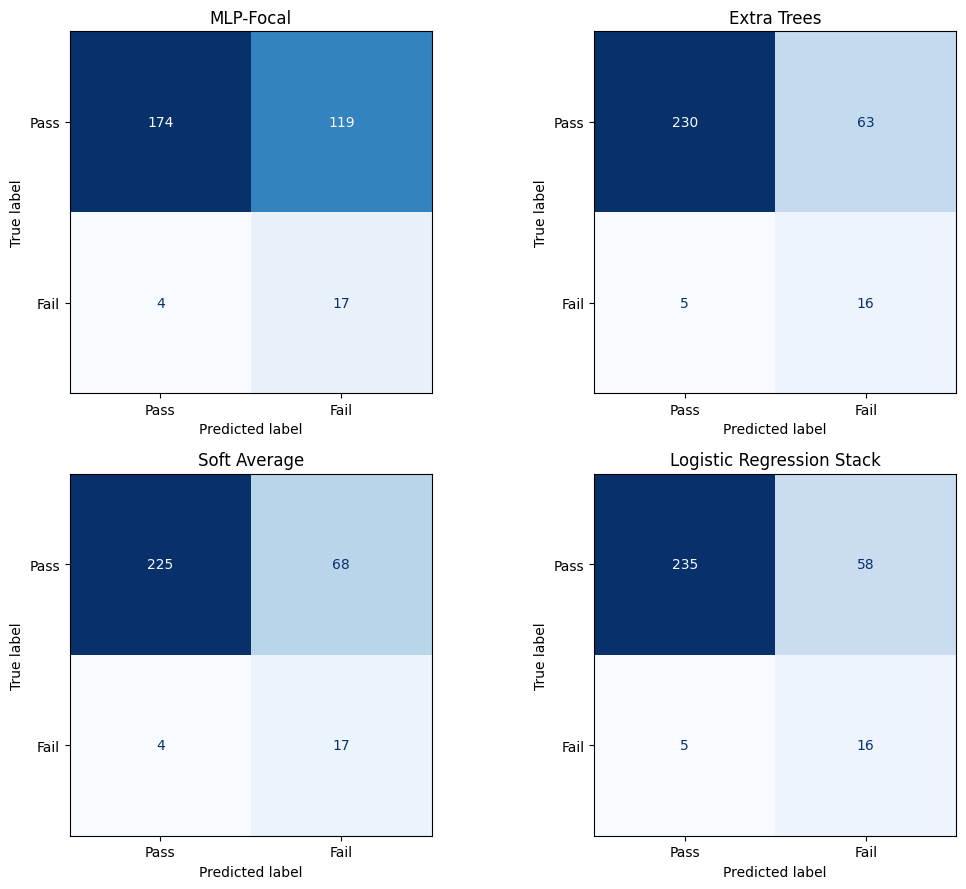

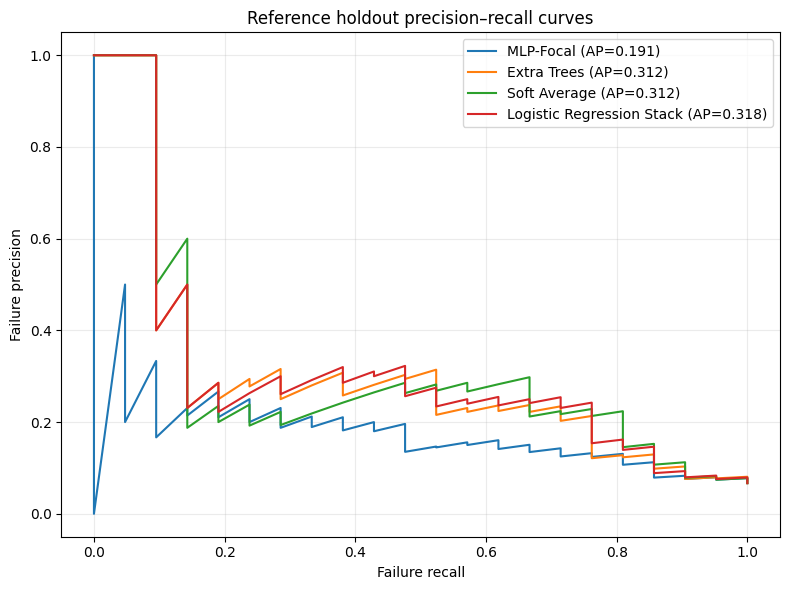

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, scores) in zip(axes.ravel(), holdout_scores.items()):
    pred = (scores >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test_np, pred,
        labels=[0, 1], display_labels=["Pass", "Fail"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name, scores in holdout_scores.items():
    precision, recall, _ = precision_recall_curve(y_test_np, scores)
    ap = average_precision_score(y_test_np, scores)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
plt.xlabel("Failure recall")
plt.ylabel("Failure precision")
plt.title("Reference holdout precision–recall curves")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 13. Inspect the learned meta-model

The Logistic Regression meta-model has only two inputs. Its coefficients show how it combines standardized MLP-Focal and Extra Trees probabilities. Coefficients are not causal explanations.

In [ ]:
meta_logistic = final_meta_model.named_steps["logistic"]
meta_coefficients = pd.DataFrame({
    "base_model_probability": ["MLP-Focal probability", "Extra Trees probability"],
    "standardized_coefficient": meta_logistic.coef_.ravel()
})
display(meta_coefficients)
print("Intercept:", float(meta_logistic.intercept_[0]))

,base_model_probability,standardized_coefficient
0,MLP-Focal probability,0.140054
1,Extra Trees probability,0.919339


Intercept: -0.4336618622723591


## 14. Save models, thresholds and experiment outputs

The `.keras` file stores the final MLP. The joblib bundle stores Extra Trees, the meta-model, MLP preprocessing objects, feature names and thresholds.

In [ ]:
OUTPUT_DIR = Path("secom_soft_stacking_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

final_mlp.save(OUTPUT_DIR / "secom_mlp_focal_base.keras")

bundle = {
    "extra_trees": final_et,
    "meta_model": final_meta_model,
    "mlp_medians": final_mlp_medians,
    "mlp_scaler": final_mlp_scaler,
    "shap_top50_features": SHAP_TOP50,
    "sensor_measurement_features": SENSOR_FEATURES,
    "missingness_indicator_sensors": MISSINGNESS_SENSORS,
    "thresholds": thresholds,
    "threshold_policy": "maximize balanced accuracy; tie-break by recall, then precision",
    "threshold_grid": {"min": THRESHOLD_MIN, "max": THRESHOLD_MAX, "points": THRESHOLD_POINTS},
    "final_mlp_epochs": final_mlp_epochs,
    "meta_class_weight": META_CLASS_WEIGHT,
    "seed": SEED
}
joblib.dump(bundle, OUTPUT_DIR / "secom_soft_stacking_bundle.joblib")

oof_results.to_csv(OUTPUT_DIR / "development_outer_oof_metrics.csv", index=False)
holdout_results.to_csv(OUTPUT_DIR / "reference_holdout_metrics.csv", index=False)
fold_summary.to_csv(OUTPUT_DIR / "outer_fold_summary.csv", index=False)

pd.DataFrame({
    "actual": y_test_np,
    "mlp_focal_probability": mlp_test_prob,
    "extra_trees_probability": et_test_prob,
    "soft_average_probability": average_test_prob,
    "stack_probability": stack_test_prob,
    "mlp_prediction": (mlp_test_prob >= thresholds["MLP-Focal"]).astype(int),
    "extra_trees_prediction": (et_test_prob >= thresholds["Extra Trees"]).astype(int),
    "soft_average_prediction": (average_test_prob >= thresholds["Soft Average"]).astype(int),
    "stack_prediction": (stack_test_prob >= thresholds["Logistic Regression Stack"]).astype(int)
}).to_csv(OUTPUT_DIR / "reference_holdout_predictions.csv", index=False)

pd.DataFrame({
    "actual": y_dev_np,
    "mlp_oof_probability": oof_mlp_prob,
    "extra_trees_oof_probability": oof_et_prob,
    "soft_average_oof_probability": oof_average_prob,
    "stack_outer_oof_probability": oof_stack_prob
}).to_csv(OUTPUT_DIR / "development_oof_predictions.csv", index=False)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)

Saved files:
 - development_oof_predictions.csv
 - development_outer_oof_metrics.csv
 - outer_fold_summary.csv
 - reference_holdout_metrics.csv
 - reference_holdout_predictions.csv
 - secom_mlp_focal_base.keras
 - secom_soft_stacking_bundle.joblib


## 15. Interpretation checklist

When reviewing the results:

1. Compare **PR-AUC / Average Precision** for ranking quality under class imbalance.
2. Compare failure recall and precision at thresholds selected from development outer-OOF predictions using the original balanced-accuracy-first policy.
3. Compare F1 and F2, false alarms, and missed failures.
4. Check whether stacking improves over both base models and the simple probability average. If it does not, prefer the simpler model.
5. Do not describe a small improvement on 21 holdout failures as conclusive. One additional detected failure changes recall by about 4.76 percentage points.

### Generalization caveat

The fixed Top-50 list was selected in the previous experiment using SHAP results that included the earlier holdout. Reusing the same reference split here does **not** restore independence. Treat these holdout scores as exploratory comparisons. For an unbiased final report, repeat statistical feature screening and SHAP ranking using training data only within each outer fold, then evaluate the complete selected procedure on a genuinely untouched test set.